# Customer Cluster Analysis

This notebook analyses the customer segments created in the PCA and K-Means.

The goal is to understand how the clusters are different in terms of demographics, spending behaviour, and purchase channels.

## 1. Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../marketing_campaign_clustered.csv")

campaign_cols = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

analysis_df = df.drop(columns=campaign_cols, errors="ignore")
analysis_df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,Complain,Z_CostContact,Z_Revenue,Children,TotalSpending,TotalPurchases,Age,Cluster
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,4,7,0,3,11,0,1617,22,57,3
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,2,5,0,3,11,2,27,4,60,1
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,10,4,0,3,11,0,776,20,49,2
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,4,6,0,3,11,1,53,6,30,5
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,6,5,0,3,11,1,422,14,33,4


In [3]:
analysis_df.shape

(2212, 28)

In [4]:
"Cluster" in analysis_df.columns

True

The campaign response columns are removed from the working dataset so this notebook stays focused only on cluster analysis.

In [5]:
analysis_df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Z_CostContact', 'Z_Revenue', 'Children', 'TotalSpending',
       'TotalPurchases', 'Age', 'Cluster'],
      dtype='str')

In [6]:
analysis_df[
    ["Income", "Age", "Children", "Recency", "TotalSpending", "TotalPurchases", "Cluster"]
].head()

,Income,Age,Children,Recency,TotalSpending,TotalPurchases,Cluster
0,58138.0,57,0,58,1617,22,3
1,46344.0,60,2,38,27,4,1
2,71613.0,49,0,26,776,20,2
3,26646.0,30,1,26,53,6,5
4,58293.0,33,1,94,422,14,4


## 2. Cluster Sizes

First, we check how many customers are in each cluster.

In [7]:
cluster_counts = analysis_df["Cluster"].value_counts().sort_index()
cluster_percent = (cluster_counts / len(analysis_df) * 100).round(2)

cluster_sizes = pd.DataFrame({
    "Count": cluster_counts,
    "Percent": cluster_percent
})

cluster_sizes

,Count,Percent
Cluster,,
0,270,12.21
1,369,16.68
2,371,16.77
3,381,17.22
4,382,17.27
5,439,19.85


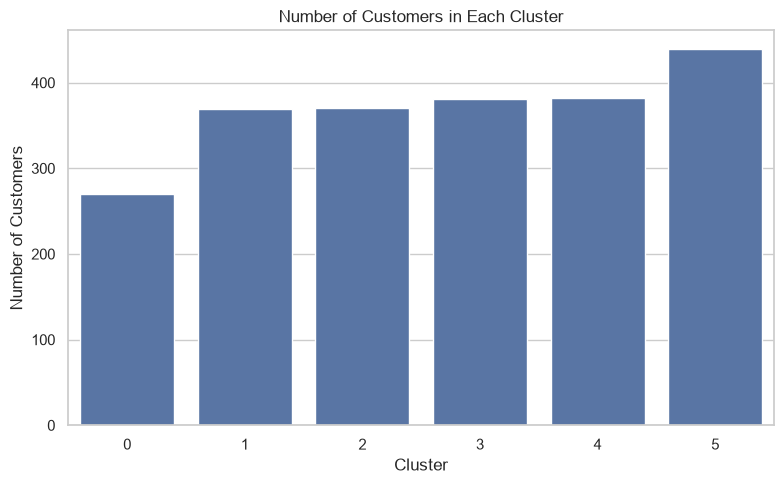

In [8]:
plt.figure(figsize=(8, 5))
sns.barplot(x=cluster_sizes.index, y=cluster_sizes["Count"])
plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

The clusters are reasonably balanced because each cluster contains a meaningful number of customers. There are no extremely small clusters that would be difficult to interpret.

## 3. Core Cluster Profile

These are the same main variables that were used to create the clusters.

In [9]:
core_cols = [
    "Income",
    "Age",
    "Children",
    "Recency",
    "TotalSpending",
    "TotalPurchases"
]

core_profile = analysis_df.groupby("Cluster")[core_cols].mean().round(2)
core_profile

,Income,Age,Children,Recency,TotalSpending,TotalPurchases
Cluster,,,,,,
0,77445.49,34.68,0.07,47.80,1482.98,20.07
1,42574.72,54.34,1.84,55.65,172.64,7.77
2,65543.83,51.74,0.80,22.27,912.24,18.06
3,69315.64,53.13,0.69,73.75,1131.79,19.24
4,34057.42,36.98,0.97,75.11,143.38,6.90
5,33204.05,38.17,1.07,22.63,124.70,6.48


For the heatmap, the values are scaled only for easier comparison. A high value means the cluster is above average for that variable, and a low value means it is below average.

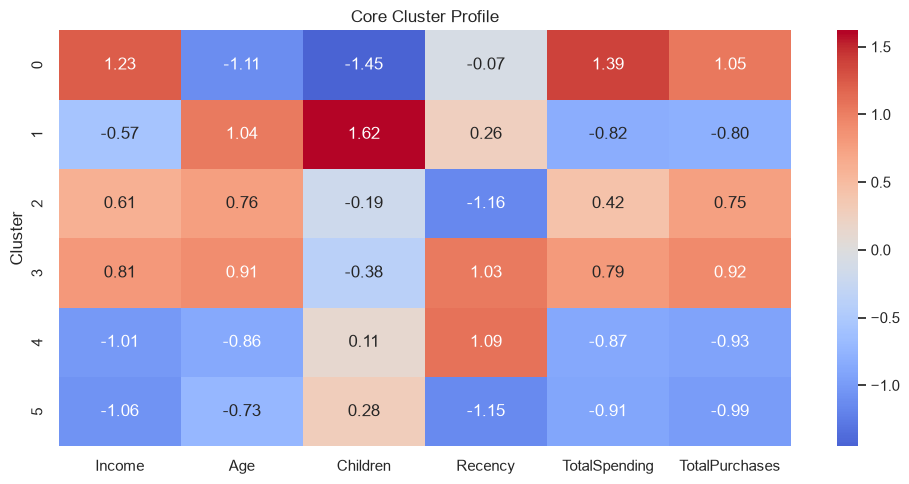

In [10]:
core_profile_scaled = (core_profile - core_profile.mean()) / core_profile.std()

plt.figure(figsize=(10, 5))
sns.heatmap(core_profile_scaled, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Core Cluster Profile")
plt.tight_layout()
plt.show()

Based on the core variables:

- Cluster 0 has the highest income and spending, with very few children.
- Cluster 1 is older, has the most children, and has low spending.
- Cluster 2 is older, higher value, and has recent purchasing activity.
- Cluster 3 is older and high value, but has less recent purchasing activity.
- Cluster 4 is younger, lower income, low spending, and less recent.
- Cluster 5 is younger, lower income, low spending, but more recent.

## 4. Product Spending Profile

This section compares what each cluster spends on different product categories.

In [11]:
product_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

product_profile = analysis_df.groupby("Cluster")[product_cols].mean().round(2)
product_profile

,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
Cluster,,,,,,
0,664.57,67.77,502.86,97.21,74.09,76.47
1,99.64,4.51,34.77,7.35,4.99,21.38
2,492.86,40.82,218.32,56.94,37.44,65.86
3,603.70,44.95,300.17,64.60,48.35,70.02
4,58.15,8.69,34.79,11.80,8.35,21.60
5,54.72,6.12,27.84,9.28,5.65,21.10


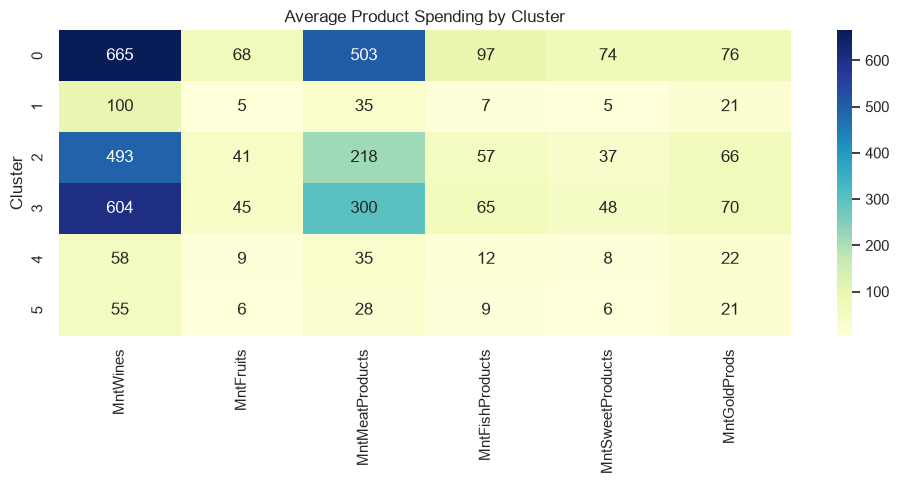

In [12]:
plt.figure(figsize=(10, 5))
sns.heatmap(product_profile, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Average Product Spending by Cluster")
plt.tight_layout()
plt.show()

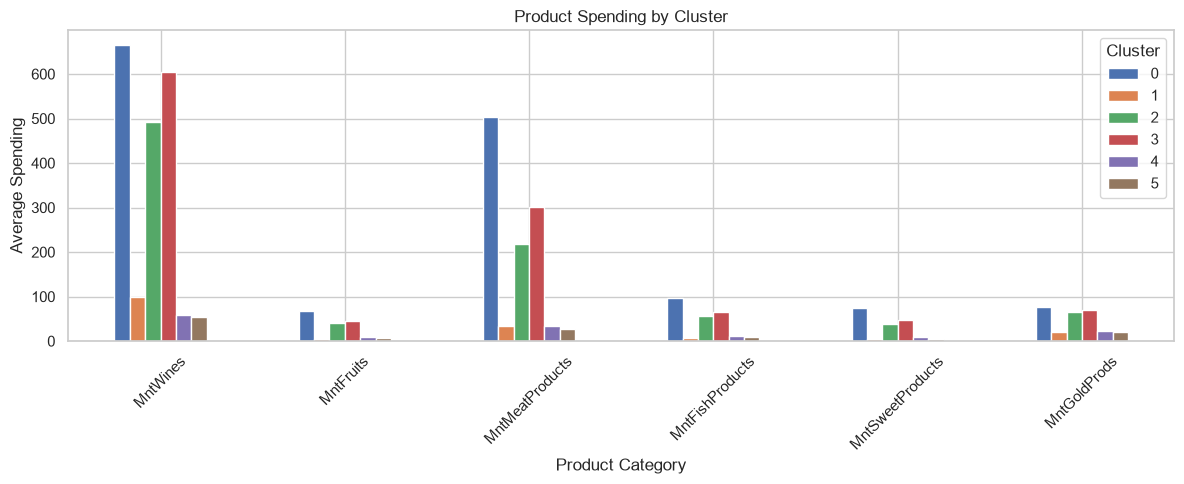

In [13]:
product_profile.T.plot(kind="bar", figsize=(12, 5))
plt.title("Product Spending by Cluster")
plt.xlabel("Product Category")
plt.ylabel("Average Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Clusters 0, 2, and 3 spend much more than the other clusters. Wine is the largest product category in most clusters, and meat products are especially important for Cluster 0. Clusters 1, 4, and 5 have much lower spending across all product categories.

## 5. Purchase Channel Profile

This section compares how customers in each cluster make purchases.

In [14]:
channel_cols = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumDealsPurchases",
    "NumWebVisitsMonth"
]

channel_profile = analysis_df.groupby("Cluster")[channel_cols].mean().round(2)
channel_profile

,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth
Cluster,,,,,
0,5.16,6.08,8.83,1.14,2.79
1,2.93,0.92,3.92,3.07,6.17
2,6.06,3.92,8.08,2.75,4.67
3,5.86,5.07,8.31,2.41,4.16
4,2.62,0.73,3.55,2.16,6.59
5,2.47,0.60,3.40,2.13,6.63


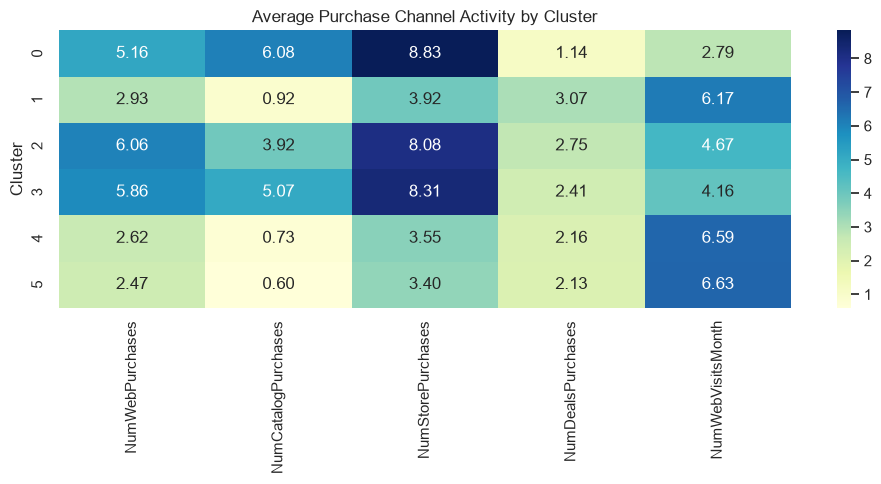

In [15]:
plt.figure(figsize=(10, 5))
sns.heatmap(channel_profile, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Purchase Channel Activity by Cluster")
plt.tight_layout()
plt.show()

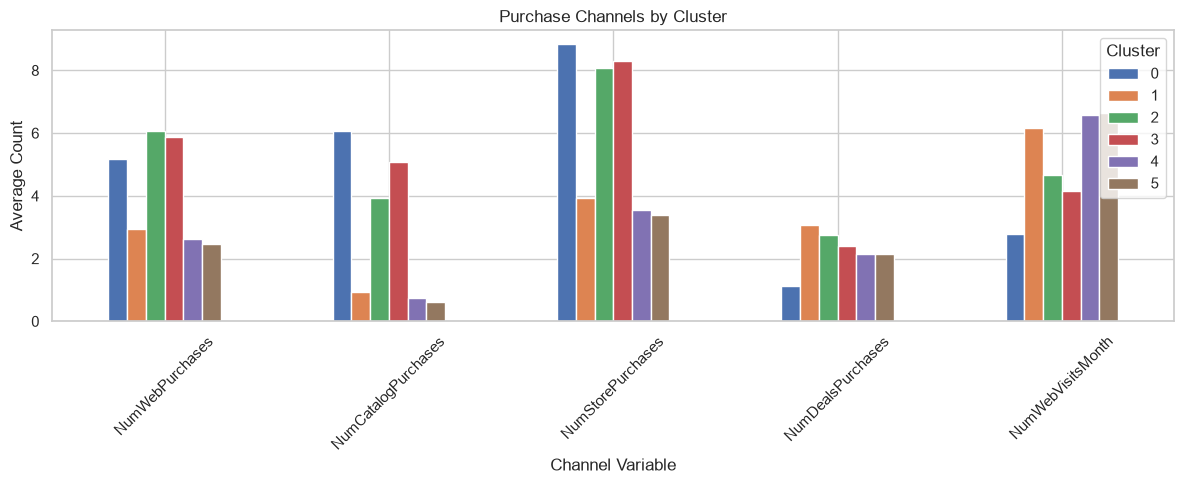

In [16]:
channel_profile.T.plot(kind="bar", figsize=(12, 5))
plt.title("Purchase Channels by Cluster")
plt.xlabel("Channel Variable")
plt.ylabel("Average Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Clusters 0, 2, and 3 make more purchases overall. Store purchases are important for these high-value clusters. Cluster 0 also has the highest catalog purchases. Clusters 1, 4, and 5 have fewer purchases but more web visits, which means they browse more than they buy.

## 6. Demographic Profile

This section compares basic demographic differences between the clusters.

In [17]:
demo_cols = ["Income", "Age", "Children"]

demo_profile = analysis_df.groupby("Cluster")[demo_cols].mean().round(2)
demo_profile

,Income,Age,Children
Cluster,,,
0,77445.49,34.68,0.07
1,42574.72,54.34,1.84
2,65543.83,51.74,0.80
3,69315.64,53.13,0.69
4,34057.42,36.98,0.97
5,33204.05,38.17,1.07


The next tables show the percentage of each education and marital status group inside each cluster.

In [18]:
education_table = pd.crosstab(
    analysis_df["Cluster"],
    analysis_df["Education"],
    normalize="index"
) * 100

education_table.round(1)

Education,2n Cycle,Basic,Graduation,Master,PhD
Cluster,,,,,
0,8.5,0.4,52.6,15.6,23.0
1,5.1,1.1,46.3,20.1,27.4
2,8.9,0.0,52.0,14.8,24.3
3,5.5,0.0,51.2,15.7,27.6
4,12.6,5.5,53.7,14.9,13.4
5,12.3,6.4,47.6,17.5,16.2


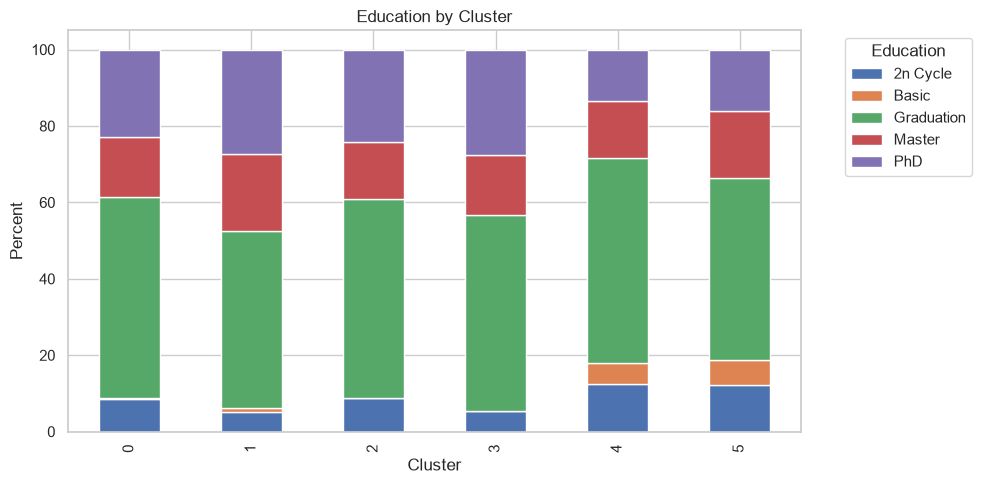

In [19]:
education_table.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Education by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Percent")
plt.legend(title="Education", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [20]:
marital_table = pd.crosstab(
    analysis_df["Cluster"],
    analysis_df["Marital_Status"],
    normalize="index"
) * 100

marital_table.round(1)

Marital_Status,Absurd,Alone,Divorced,Married,Single,Together,Widow,YOLO
Cluster,,,,,,,,
0,0.4,0.0,8.1,36.3,28.5,25.9,0.7,0.0
1,0.0,0.0,11.4,36.3,17.6,30.6,4.1,0.0
2,0.3,0.3,12.4,37.2,17.5,27.0,5.4,0.0
3,0.0,0.0,12.9,39.1,17.8,23.9,6.3,0.0
4,0.0,0.0,8.6,37.4,26.7,25.4,1.8,0.0
5,0.0,0.5,8.9,44.4,21.2,22.8,1.8,0.5


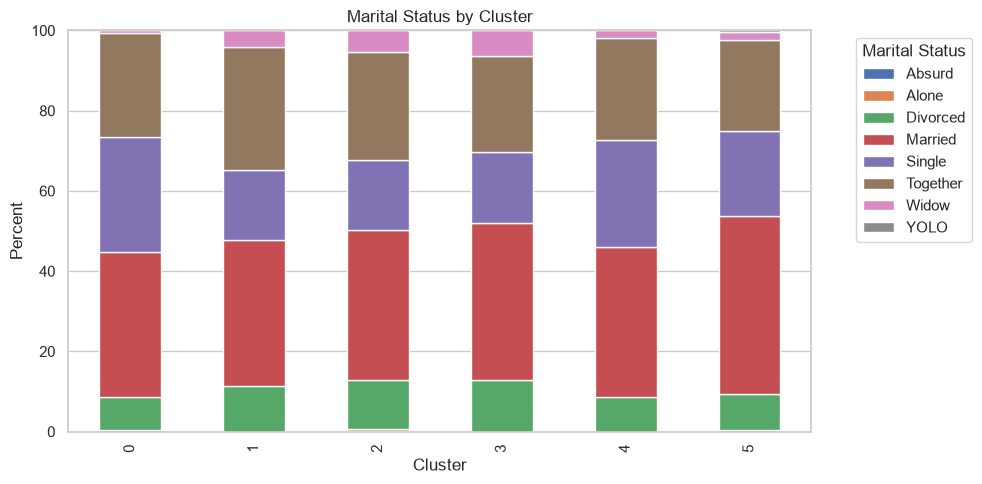

In [21]:
marital_table.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Marital Status by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Percent")
plt.legend(title="Marital Status", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

The strongest demographic differences are age, income, and number of children. Education and marital status are useful for describing the groups, but they do not separate the clusters as strongly as spending and household variables.

## 7. Cluster Labels

Based on the profiles above, each cluster can be given a simple descriptive name.

In [22]:
cluster_names = pd.DataFrame({
    "Cluster": [0, 1, 2, 3, 4, 5],
    "Suggested Cluster Name": [
        "Young Premium Customers",
        "Older Family Budget Customers",
        "Established High-Value Recent Customers",
        "Older High-Value Less Recent Customers",
        "Young Low-Value Inactive Customers",
        "Young Low-Value Recent Customers"
    ]
})

cluster_names

,Cluster,Suggested Cluster Name
0,0,Young Premium Customers
1,1,Older Family Budget Customers
2,2,Established High-Value Recent Customers
3,3,Older High-Value Less Recent Customers
4,4,Young Low-Value Inactive Customers
5,5,Young Low-Value Recent Customers


## 8. Final Summary

In [23]:
summary = pd.DataFrame({
    "Cluster": [0, 1, 2, 3, 4, 5],
    "Suggested Cluster Name": [
        "Young Premium Customers",
        "Older Family Budget Customers",
        "Established High-Value Recent Customers",
        "Older High-Value Less Recent Customers",
        "Young Low-Value Inactive Customers",
        "Young Low-Value Recent Customers"
    ],
    "Key Characteristics": [
        "Highest income and spending, very few children, strong catalog and store purchases",
        "Older customers, many children, low spending, more deal purchases",
        "Older high-value customers, recent purchases, strong web and store activity",
        "Older high-value customers, high spending, but less recent purchases",
        "Younger customers, low income, low spending, less recent purchases",
        "Younger customers, low income, low spending, but recent purchases"
    ],
    "Possible Business Meaning": [
        "Important premium segment with strong buying power",
        "Budget-conscious family segment",
        "Loyal and active high-value segment",
        "Valuable customers who may need re-engagement",
        "Low-value segment with weak recent activity",
        "Recent but low-value segment that may still develop"
    ]
})

summary

,Cluster,Suggested Cluster Name,Key Characteristics,Possible Business Meaning
0,0,Young Premium Customers,"Highest income and spending, very few children...",Important premium segment with strong buying p...
1,1,Older Family Budget Customers,"Older customers, many children, low spending, ...",Budget-conscious family segment
2,2,Established High-Value Recent Customers,"Older high-value customers, recent purchases, ...",Loyal and active high-value segment
3,3,Older High-Value Less Recent Customers,"Older high-value customers, high spending, but...",Valuable customers who may need re-engagement
4,4,Young Low-Value Inactive Customers,"Younger customers, low income, low spending, l...",Low-value segment with weak recent activity
5,5,Young Low-Value Recent Customers,"Younger customers, low income, low spending, b...",Recent but low-value segment that may still de...


Overall, the clusters show clear differences in customer value, household situation, recency, and purchase channels. The most valuable groups are Clusters 0, 2, and 3 because they have higher income, spending, and purchase activity. Clusters 1, 4, and 5 are lower-value groups, but they differ in age, children, and recency.